In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT", "A1", "PSD", "RIM"]
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi"
)
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": channels})

In [ ]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1, name=channels)

# 2. Drift correction

In [3]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X", "Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 500
a = data[0, 2, :, :n, :n].max(axis=1)
b = stabilized[0, 2, :, :n, :n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False, cmap="gray")
plt.subplot(312)
b.plot(add_colorbar=False, cmap="gray")
plt.subplot(313)
plt.imshow(np.stack([a, b, a], axis=2), aspect=4)
plt.suptitle("Z drift correction")
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 3. Spot detection

- Detect spots in all channels

(<Figure size 2000x2000 with 4 Axes>,
 {'A1': <Axes: title={'center': 'A1'}>,
  'PRRT': <Axes: title={'center': 'PRRT'}>,
  'PSD': <Axes: title={'center': 'PSD'}>,
  'RIM': <Axes: title={'center': 'RIM'}>})

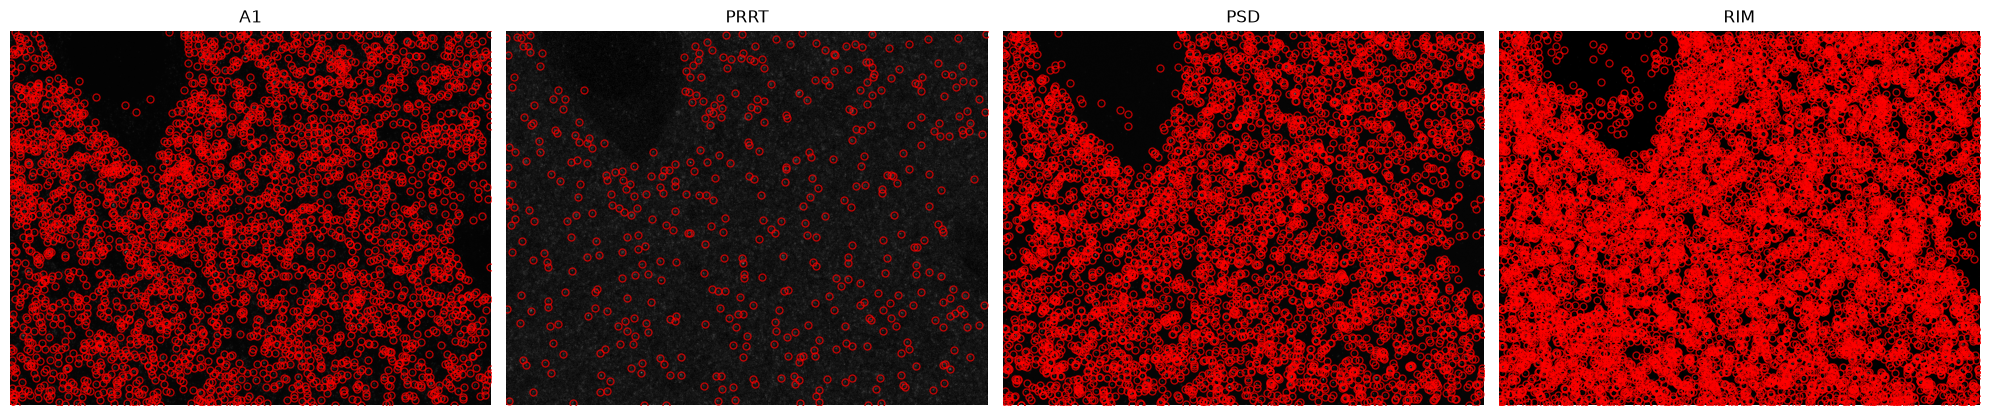

In [11]:
import matplotlib.pyplot as plt
import numpy as np

from prrt_clustering import detect_puncta, plot_data, plot_points

tmp = stabilized[0]#, :, :, 250:500, 800:1000]
parameters = {
    "PRRT": {"scale_um": 0.4, "specificity": 6},
    "A1": {"scale_um": 0.3, "specificity": 6},
    "PSD": {"scale_um": 0.1, "specificity": 8},
    "RIM": {"scale_um": 0.1, "specificity": 6},
}

points = detect_puncta(tmp, parameters)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
plot_points(points, ms=10, split=True, axes_dict=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
for n, pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
    v.add_points(pts[["Z", "Y", "X"]], size=0.5, name=n, face_color=fcol[n])

## 3. Clustering of RIM and PSD channels
Cluster points to identify potential synapses.

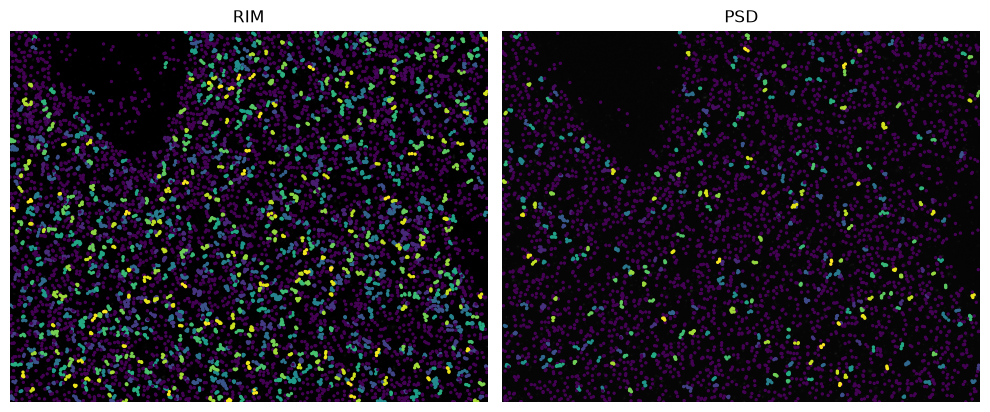

In [16]:
from prrt_clustering import cluster_dbscan

points, clusters = cluster_dbscan(points, eps=1.5, min_samples=3)

fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp.sel(C=["RIM", "PSD"]), split=True, fig=fig)
for n, g in points[points["C"].isin(["RIM", "PSD"])].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["cluster_id"], s=2)


## 4. Pre-post synpatic cluster association
Identify synapses as pair of cluster

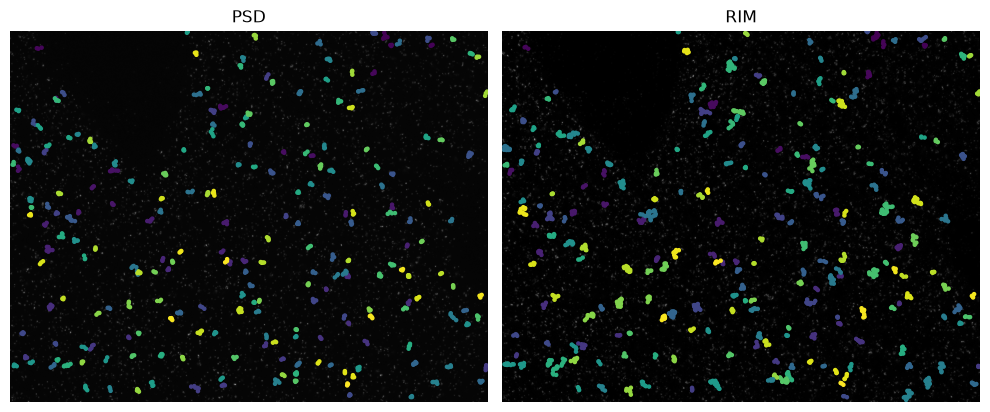

In [17]:
from prrt_clustering import pair_cluster

points, synapses = pair_cluster(points, ["PSD", "RIM"], distance=1)

fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp.sel(C=["PSD", "RIM"]), split=True, fig=fig)
for n, g in points[points["synapse_id"] >= 0].groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=5)


## 5. Identify pair of A1-PRRT

Identify pair of A1-PRRT puncta


In [18]:
from prrt_clustering import pair_puncta

points, pairs = pair_puncta(points, ["A1", "PRRT"], distance=0.5)

## 6. Synapse profiling

For each synapse, associate the puncate in all channel


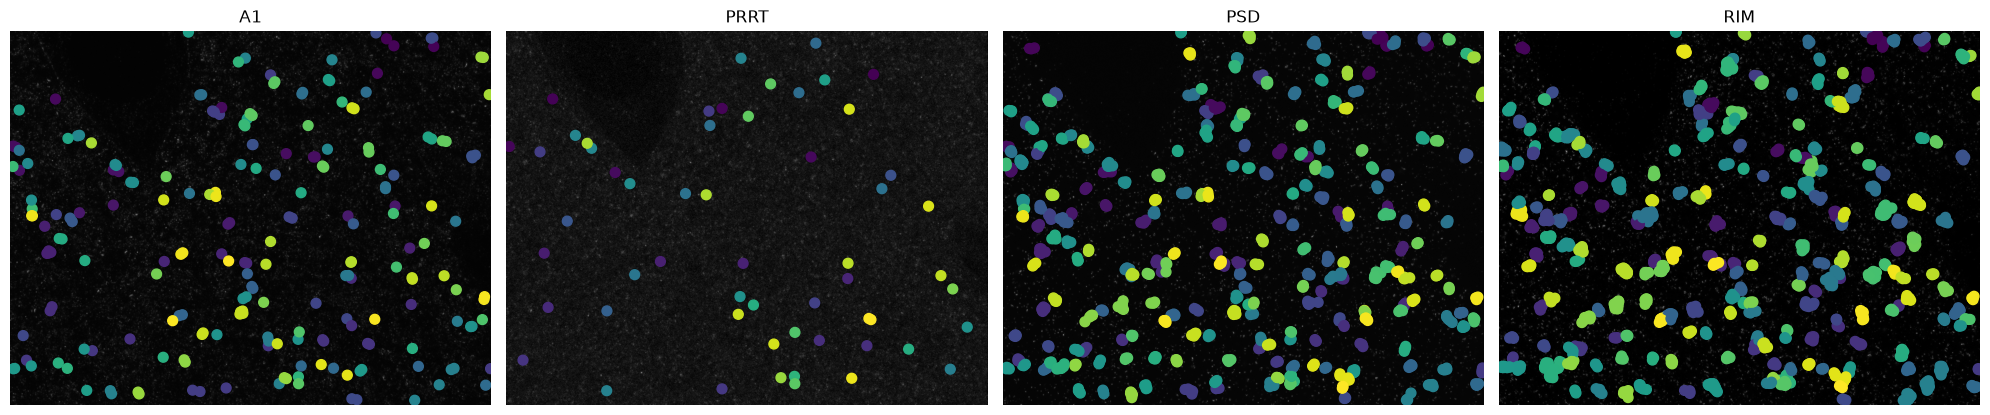

In [19]:
from prrt_clustering.clustering import associate_to_paired_cluster, compute_distances

points = associate_to_paired_cluster(points, 0.5)
points = compute_distances(points)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
for n, g in points.groupby("C"):
    axes[n].scatter(g["X"], g["Y"], c=g["synapse_id"], s=50)


In [ ]:
from prrt_clustering import global_stats, synapse_stats

global_stats(points, 1, 3)

TypeError: unsupported operand type(s) for -: 'str' and 'int'

In [27]:
import numpy as np
np.ptp(points[["Z", "Y", "X"]].to_numpy(),axis=0)

array([  3.6       , 164.84560126, 211.99445469])

In [22]:
synapse_stats(points)

,synapse,Number of RIM puncta,Number of PSD puncta,Number of A1 puncta,Number of PRRT puncta,Number of A1-PRRT complex,Mean distance PRRT:PSD,Mean distance PRRT:RIM,Mean distance A1:PSD,Mean distance A1:RIM,Mean distance PRRT:A1
0,0,11,7,1,0,0,NaN,NaN,0.304607,0.686972,NaN
1,1,3,3,1,0,0,NaN,NaN,0.261900,0.746688,NaN
2,2,4,3,1,0,0,NaN,NaN,0.236778,0.547903,NaN
3,3,3,3,0,0,0,NaN,NaN,NaN,NaN,NaN
4,4,8,3,1,1,2,0.391787,0.628643,0.092992,0.635850,0.478107
...,...,...,...,...,...,...,...,...,...,...,...
232,232,4,3,2,0,0,NaN,NaN,0.328819,0.443524,NaN
233,233,9,5,1,2,2,0.115674,0.510831,0.299308,0.441285,0.713773
234,234,10,4,1,0,0,NaN,NaN,0.229555,0.438901,NaN
235,235,5,3,1,0,0,NaN,NaN,0.106438,1.399465,NaN
